# Supplementary Fig S7 · Dyadic decomposition of a partial query

Explains Spindle-Partial (cited from Methods 3.7 and Supplementary B.7). Breast, the largest niche, its most
co-varying block of 20-32 genes (seed-0 Spindle-Partial index); an illustrative gene set of 13 genes inside the block.

* **A** the block's genes in the niche's gene order, the gene set S, its maximal runs, and every aligned dyadic interval
  of the block by length s (grey); the query's pieces I_1 ... I_s (yellow), the fewest dyadic intervals covering
  each run from left to right (`SpindlePartial` niche `pieces`), with their node counts K_I.
* **B** the niche's mean correlation on S in block order (diagonal not shown): d_P uses the entries inside the pieces (outlined), and
  leaves out the entries between pieces of the same block (hatched), which d_B^S keeps.
* **C** the pieces as the layers of the search: K_I nodes per layer and the path of one index tile.

**Run first:** `R10_block_structure` (`results/block_structure/dyadic_example.npz`). Writes `figures/figS7_dyadic/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

import style as ps

FIG = "figS7_dyadic"
RES = ROOT / "results" / "block_structure"
PIECE = ps.TIER_COLORS["spindle_partial"]
CMAP = ps.DIVERGING
H = 70.0
VMAX = 0.5

z = np.load(RES / "dyadic_example.npz")
names, S = z["names"], z["positions"]
pieces, K = z["pieces"], z["piece_K"]          # (s, j) of each piece, left to right; K_I
intervals = z["intervals"]                       # (s, j, K_I) of every aligned dyadic interval of the block
p_b = len(names)
runs = np.split(S, np.flatnonzero(np.diff(S) > 1) + 1)
# the example tile: the first index tile whose path uses the most distinct node numbers
paths = z["paths"].astype(int)
tile = int(np.argmax([len(set(r)) for r in paths]))
path = paths[tile]
print(f"block {int(z['block'])} of niche {int(z['niche'])}: {p_b} genes, {len(intervals)} dyadic intervals "
      f"(< 2 p_b = {2 * p_b}); S = {S.tolist()}; runs {[(int(r[0]), int(r[-1]) + 1) for r in runs]}; "
      f"pieces (s, j) {pieces.tolist()}, K {K.tolist()}; tile row {tile}, path {path.tolist()}")

block 10 of niche 0: 28 genes, 53 dyadic intervals (< 2 p_b = 56); S = [2, 3, 4, 5, 6, 7, 8, 11, 12, 16, 17, 18, 19]; runs [(2, 9), (11, 13), (16, 20)]; pieces (s, j) [[2, 2], [4, 4], [1, 8], [1, 11], [1, 12], [4, 16]], K [128, 128, 32, 32, 32, 128]; tile row 2, path [118, 96, 28, 0, 17, 107]


## A · The block, the gene set, its runs and its dyadic pieces

figures/figS7_dyadic/panels/A.pdf/.png: 112 x 70 mm, 0.0 / 0.4 MB


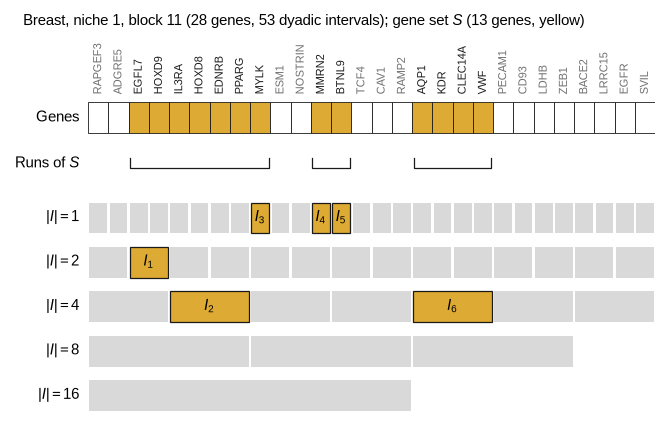

In [2]:
def panel_a(fig):
    W, Hp = ps.size_mm(fig)
    ax = ps.axes(fig, left=15.0, right=1.0, bottom=1.0, top=15.0)
    levels = sorted(set(intervals[:, 0].tolist()))
    y_gene, y_run = 0.0, -1.1
    y_lvl = {s: -2.6 - i * 1.15 for i, s in enumerate(levels)}
    inS = np.zeros(p_b, bool); inS[S] = True
    for i in range(p_b):
        ax.add_patch(Rectangle((i, y_gene), 1, 0.8, fc=PIECE if inS[i] else "white", ec=ps.INK, lw=0.4,
                               alpha=1.0))
        ax.text(i + 0.5, y_gene + 1.0, names[i], rotation=90, ha="center", va="bottom", fontsize=5.5,
                color=ps.INK if inS[i] else ps.MUTED)
    for r in runs:
        a, e = r[0], r[-1] + 1
        ax.plot([a + 0.08, a + 0.08, e - 0.08, e - 0.08], [y_run + 0.45, y_run + 0.2, y_run + 0.2, y_run + 0.45],
                color=ps.INK, lw=0.6)
    piece_set = {(int(s), int(j)): t for t, (s, j) in enumerate(pieces)}
    for s, j, k in intervals:
        y = y_lvl[int(s)]
        t = piece_set.get((int(s), int(j)))
        if t is None:
            ax.add_patch(Rectangle((j + 0.06, y), s - 0.12, 0.8, fc=ps.LIGHT, ec="none"))
        else:
            ax.add_patch(Rectangle((j + 0.06, y), s - 0.12, 0.8, fc=PIECE, ec=ps.INK, lw=0.6))
            ax.text(j + s / 2, y + 0.4, f"$I_{t + 1}$", ha="center", va="center", fontsize=ps.TICK_PT)
    labels = {y_gene + 0.4: "Genes", y_run + 0.3: "Runs of $S$"}
    labels.update({y_lvl[s] + 0.4: f"$|I|={s}$" for s in levels})
    for y, lab in labels.items():
        ax.text(-0.4, y, lab, ha="right", va="center", fontsize=ps.TICK_PT)
    ax.set_xlim(0, p_b)
    ax.set_ylim(min(y_lvl.values()) - 0.2, y_gene + 0.85)
    ax.axis("off")
    fig.text(4.0 / W, 1 - 0.5 / Hp, f"Breast, niche {int(z['niche']) + 1}, block {int(z['block']) + 1} "
             f"({p_b} genes, {len(intervals)} dyadic intervals); gene set $S$ ({len(S)} genes, yellow)",
             va="top", fontsize=ps.TICK_PT)


fig = ps.panel(112, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · What d_P keeps and leaves out

figures/figS7_dyadic/panels/B.pdf/.png: 66 x 40 mm, 0.0 / 0.3 MB


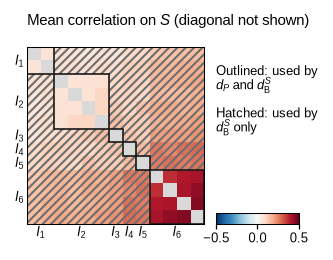

In [3]:
def panel_b(fig):
    W, Hp = ps.size_mm(fig)
    C = z["corr"].astype(float)[np.ix_(S, S)]
    np.fill_diagonal(C, np.nan)
    n = len(S)
    side = 30.0
    ax = fig.add_axes([9.0 / W, 1 - (6.0 + side) / Hp, side / W, side / Hp])
    cmap = plt.get_cmap(CMAP).copy(); cmap.set_bad(ps.LIGHT)
    ax.imshow(C, cmap=cmap, vmin=-VMAX, vmax=VMAX, interpolation="nearest")
    starts = np.searchsorted(S, pieces[:, 1])        # piece t covers S indices starts[t] .. starts[t] + s - 1
    keep = np.zeros((n, n), bool)
    for (s, _), a in zip(pieces, starts):
        keep[a:a + s, a:a + s] = True
    for i in range(n):
        for j in range(n):
            if not keep[i, j]:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="//////", ec=ps.MUTED, lw=0))
    for t, ((s, _), a) in enumerate(zip(pieces, starts)):
        ax.add_patch(Rectangle((a - 0.5, a - 0.5), s, s, fill=False, ec=ps.INK, lw=0.8))
    mids = [a + (s - 1) / 2 for (s, _), a in zip(pieces, starts)]
    ax.set_xticks(mids, [f"$I_{t + 1}$" for t in range(len(pieces))], fontsize=ps.TICK_PT - 1)
    ax.set_yticks(mids, [f"$I_{t + 1}$" for t in range(len(pieces))], fontsize=ps.TICK_PT - 1)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_linewidth(0.5)
    fig.text(9.0 / W, 1 - 0.5 / Hp, "Mean correlation on $S$ (diagonal not shown)", va="top", fontsize=ps.TICK_PT)
    fig.text((9.0 + side + 2.0) / W, 1 - 9.0 / Hp, "Outlined: used by\n$d_P$ and $d_{\\mathcal{B}}^{S}$\n\nHatched: used by\n"
             "$d_{\\mathcal{B}}^{S}$ only", va="top", fontsize=ps.TICK_PT - 1, linespacing=1.2)
    cax = fig.add_axes([(9.0 + side + 2.0) / W, 1 - (6.0 + side) / Hp, 14.0 / W, 1.8 / Hp])
    cb = fig.colorbar(ScalarMappable(Normalize(-VMAX, VMAX), CMAP), cax=cax, orientation="horizontal",
                      ticks=[-VMAX, 0, VMAX])
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(labelsize=ps.TICK_PT - 1)


fig = ps.panel(66, 40); panel_b(fig); ps.save_panel(fig, FIG, "B")

## C · The pieces as search layers

figures/figS7_dyadic/panels/C.pdf/.png: 66 x 30 mm, 0.0 / 0.2 MB


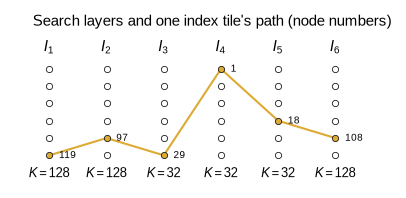

In [4]:
SHOW = 6  # node slots drawn per layer; the tile's node sits in the slot of its rank among the K_I nodes


def panel_c(fig):
    W, Hp = ps.size_mm(fig)
    ax = ps.axes(fig, left=2.0, right=2.0, bottom=1.0, top=5.0)
    m = len(pieces)
    slot = [int(round(path[t] / max(K[t] - 1, 1) * (SHOW - 1))) for t in range(m)]
    for t in range(m):
        for r in range(SHOW):
            on = r == slot[t]
            ax.scatter(t, -r, s=9, fc=PIECE if on else "white", ec=ps.INK, lw=0.4, zorder=3)
        ax.text(t + 0.17, -slot[t], str(int(path[t]) + 1), ha="left", va="center", fontsize=ps.TICK_PT - 2)
        ax.text(t, -SHOW + 0.25, f"$K={int(K[t])}$", ha="center", va="top", fontsize=ps.TICK_PT - 1)
        ax.text(t, 0.8, f"$I_{t + 1}$", ha="center", va="bottom", fontsize=ps.TICK_PT)
    for t in range(m - 1):
        ax.plot([t, t + 1], [-slot[t], -slot[t + 1]], color=PIECE, lw=1.0, zorder=2)
    ax.set_xlim(-0.6, m - 0.2)
    ax.set_ylim(-SHOW - 0.6, 1.6)
    ax.axis("off")
    fig.text(5.0 / W, 1 - 0.5 / Hp, "Search layers and one index tile's path (node numbers)", va="top",
             fontsize=ps.TICK_PT)


fig = ps.panel(66, 30); panel_c(fig); ps.save_panel(fig, FIG, "C")

## Full figure

figures/figS7_dyadic/figS7_dyadic.pdf/.png: 180 x 70 mm, 0.1 / 1.3 MB


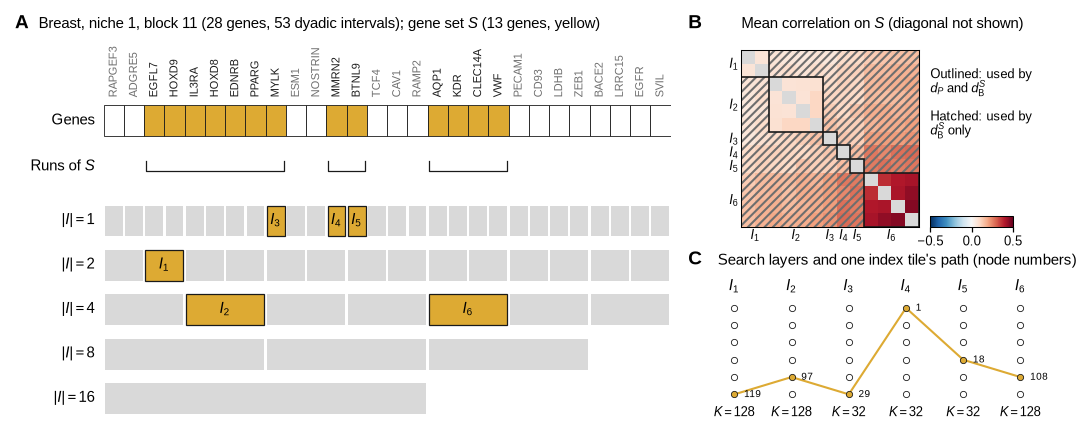

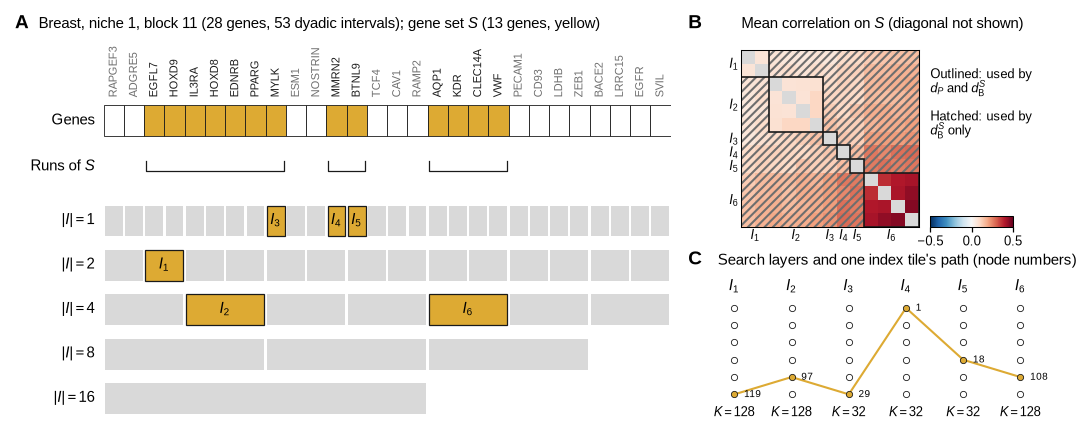

In [5]:
page = ps.page(180, H)
panel_a(ps.place(page, "A", 0, 0, 112, H))
panel_b(ps.place(page, "B", 114, 0, 66, 40))
panel_c(ps.place(page, "C", 114, 40, 66, 30))
ps.save_figure(page, FIG)
page